In [1]:
import sys
from pathlib import Path
import duckdb
import joblib
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

# 1. Cargamos el pipeline entrenado desde models/
MODEL_PATH = PROJECT_ROOT / "models" / "modelo_crediticio.joblib"
artefacto = joblib.load(MODEL_PATH)
pipeline_ganador = artefacto["pipeline"]
umbral_optimo = artefacto["umbral_optimo"]

print(f"Modelo cargado: {artefacto['nombre_modelo']} | Umbral óptimo: {umbral_optimo}")

# 2. Reconstruimos exactamente la misma partición Test (random_state=42)
DB_PATH = PROJECT_ROOT / "data" / "processed" / "credit_risk.duckdb"
con = duckdb.connect(str(DB_PATH), read_only=True)
df = con.execute("SELECT * FROM solicitudes_credito").df()
con.close()

X = df.drop(columns=["SeriousDlqin2yrs"])
y = df["SeriousDlqin2yrs"].astype(int)

_, X_test, _, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# 3. Transformamos X_test con el preprocesador ya entrenado (sin refit)
preprocessor = pipeline_ganador.named_steps["prep"]
modelo_xgb = pipeline_ganador.named_steps["clf"]

X_test_prep = preprocessor.transform(X_test)

# Tomamos una muestra representativa de 3.000 clientes de Test para agilizar el cálculo SHAP
X_sample = X_test_prep.sample(n=3000, random_state=42)
y_sample = y_test.loc[X_sample.index]

# 4. Inicializamos TreeExplainer (exacto y optimizado para modelos de árboles como XGBoost)
explainer = shap.TreeExplainer(modelo_xgb)
shap_values = explainer(X_sample)

print("Valores SHAP calculados exitosamente. Shape:", shap_values.values.shape)

c:\Users\Usuario\OneDrive\Desktop\Maxi\FACULTAD\PROYECTOS Maxi\Proyecto Scoring-Riesgo-Crediticio-ML\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Modelo cargado: XGBoost | Umbral óptimo: 0.17
Valores SHAP calculados exitosamente. Shape: (3000, 19)


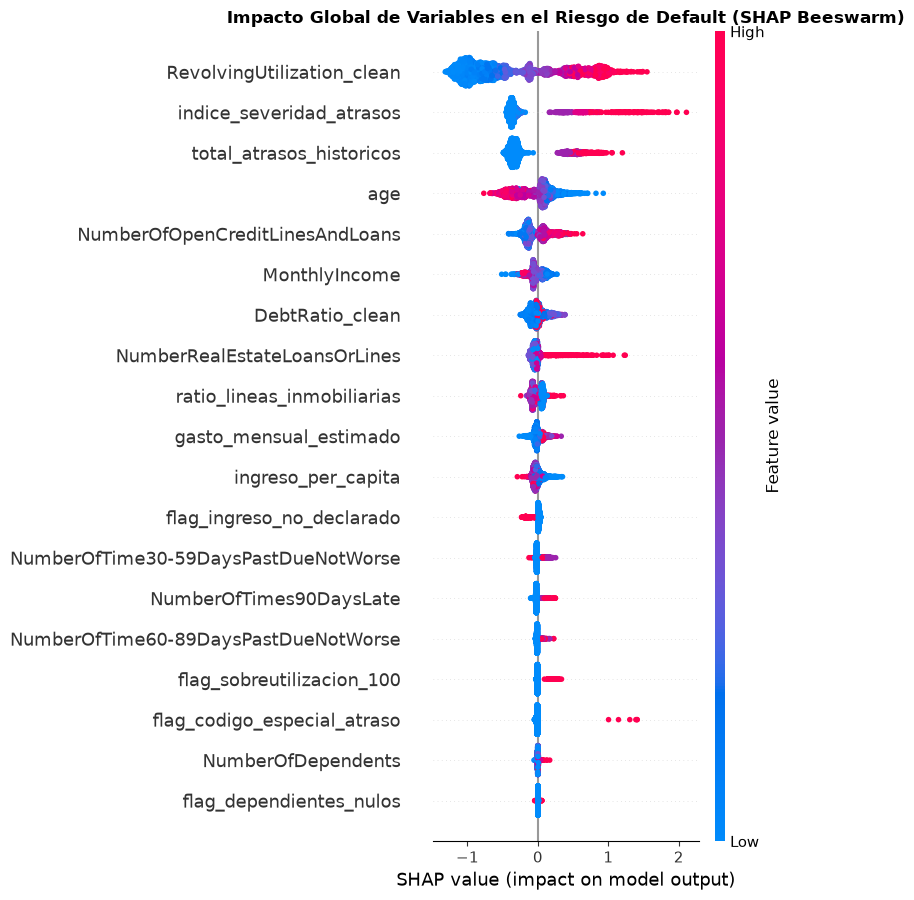

In [2]:
plt.figure(figsize=(10, 7))
shap.summary_plot(shap_values, X_sample, show=False)
plt.title("Impacto Global de Variables en el Riesgo de Default (SHAP Beeswarm)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

In [3]:
importancia_shap = pd.DataFrame({
    "Variable": X_sample.columns,
    "Importancia_Media_SHAP": np.abs(shap_values.values).mean(axis=0)
}).sort_values(by="Importancia_Media_SHAP", ascending=False)

display(importancia_shap)

,Variable,Importancia_Media_SHAP
11,RevolvingUtilization_clean,0.731851
17,indice_severidad_atrasos,0.416902
16,total_atrasos_historicos,0.383570
0,age,0.208792
3,NumberOfOpenCreditLinesAndLoans,0.141572
2,MonthlyIncome,0.085826
13,DebtRatio_clean,0.078520
5,NumberRealEstateLoansOrLines,0.065629
18,ratio_lineas_inmobiliarias,0.059033
14,gasto_mensual_estimado,0.049926


--- CASO 1: SOLICITANTE DE BAJO RIESGO (Prob. Default: 0.20% | Umbral: 17.0%) ---


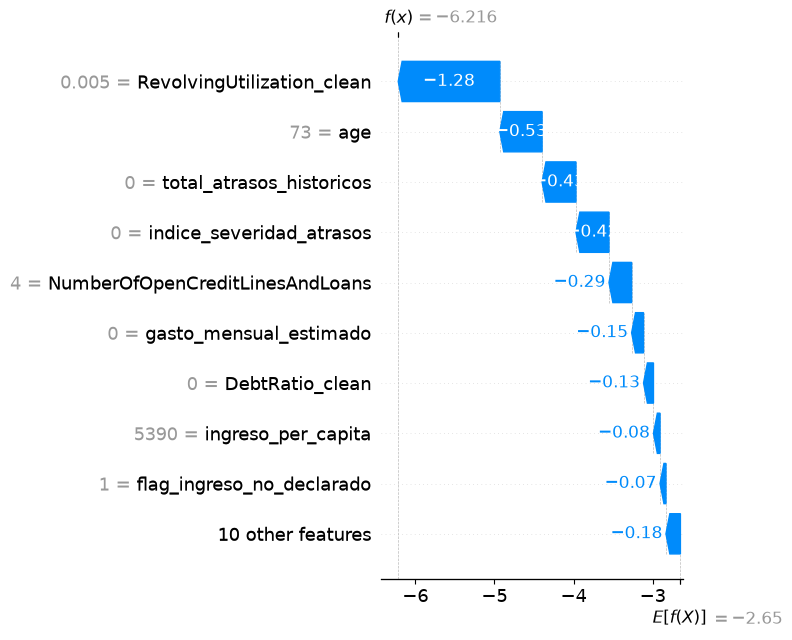


--- CASO 2: SOLICITANTE DE ALTO RIESGO (Prob. Default: 83.70% | Umbral: 17.0%) ---


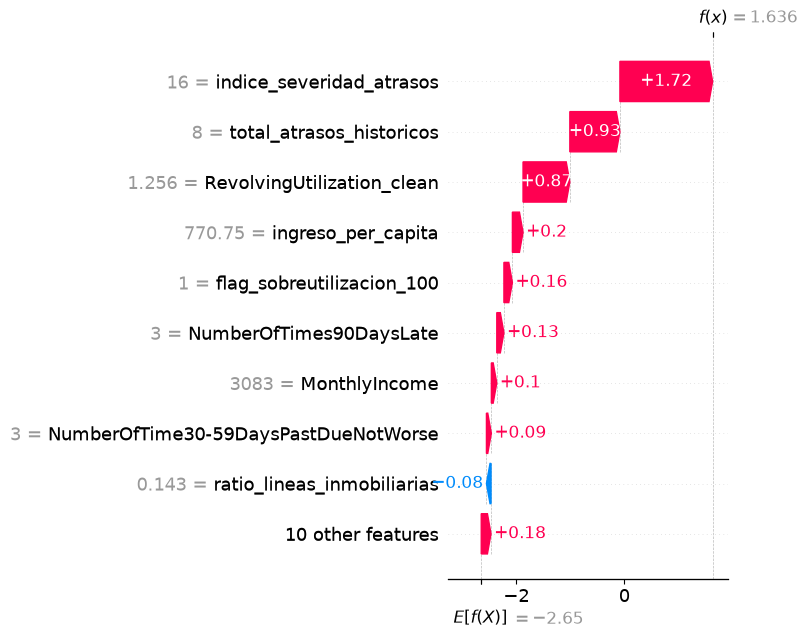

In [4]:
# Calculamos probabilidades sobre la muestra
probs_sample = modelo_xgb.predict_proba(X_sample)[:, 1]

# Buscamos un caso claro de bajo riesgo (aprobado) y uno de alto riesgo (rechazado)
idx_bajo_riesgo = int(np.argmin(probs_sample))
idx_alto_riesgo = int(np.argmax(probs_sample))

print(f"--- CASO 1: SOLICITANTE DE BAJO RIESGO (Prob. Default: {probs_sample[idx_bajo_riesgo]*100:.2f}% | Umbral: {umbral_optimo*100:.1f}%) ---")
plt.figure(figsize=(10, 5))
shap.plots.waterfall(shap_values[idx_bajo_riesgo], max_display=10, show=False)
plt.tight_layout()
plt.show()

print(f"\n--- CASO 2: SOLICITANTE DE ALTO RIESGO (Prob. Default: {probs_sample[idx_alto_riesgo]*100:.2f}% | Umbral: {umbral_optimo*100:.1f}%) ---")
plt.figure(figsize=(10, 5))
shap.plots.waterfall(shap_values[idx_alto_riesgo], max_display=10, show=False)
plt.tight_layout()
plt.show()